# Ethos before and after single-domain unlearning
Six models each have eight independently trained checkpoints: four StereoSet domains in English and four in Ukrainian. Every checkpoint has eight paired Fair-UK evaluations. Each effect compares the original model with one Ethos checkpoint on identical items in one evaluation language.

The tables show target mitigation, changes in other domains, language transfer and language-modeling score (LMS). The external benchmarks use their own bias and accuracy measures. Restart the kernel and run all cells to generate the CSV tables and both heatmaps. The [study instructions](../README.md#reproduce-the-seed-42-analysis) describe the environment and input archive.

In [1]:
import sys
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle

study_path = Path("redistibution-artifacts/ethos-stereoset")
ancestors = [Path.cwd(), *Path.cwd().parents]
study = next(
    path
    for parent in ancestors
    for path in (parent, parent / study_path)
    if (path / "analysis/seed-42/fair-uk-reports.jsonl.gz").is_file()
)
sys.path.insert(0, str(study / "ethos"))

In [2]:
from redistribution import (
    KEY,
    TOLERANCE,
    bbq_categories,
    external_rows,
    load_reports,
    stereoset_rows,
)
from suite_data import read

spec = read(study / "config/stereoset_domains.json")
reports = load_reports(study)
domains = list(spec["domains"])
labels = {"race": "race/ethnicity"}
model_names = {r["cell"]["model"]: r["model_label"] for r in reports}
models = [model_names[m] for m in spec["models"]]
languages = ["en", "uk"]
routes = list(product(languages, repeat=2))
out = study / "analysis/outputs"
out.mkdir(parents=True, exist_ok=True)

sources = pd.DataFrame(
    [
        {
            **r["cell"],
            **{
                k: r[k]
                for k in (
                    "task",
                    "evaluation_language",
                    "job",
                    "rows",
                    "pair",
                    "receipt_sha256",
                    "paired_sha256",
                    "training_sha256",
                    "dataset_sha256",
                    "source_rows_sha256",
                    "evaluator_revision",
                )
            },
        }
        for r in reports
    ]
)
display(
    sources.groupby("task").agg(paired_evaluations=("job", "size"), rows_per_pair=("rows", "first"))
)

,paired_evaluations,rows_per_pair
task,,
bbq_en,48,58492
bbq_uk,48,58492
stereoset_en,48,949
stereoset_uk,48,949
winobias_en_controlled,48,1580
winobias_en_natural,48,558
winobias_uk_controlled,48,1580
winobias_uk_natural,48,1674


## StereoSet scoring
The native target-macro stereotype score (SS) gives each named target within a domain equal weight. An SS of 50 is parity. Bias magnitude is `abs(SS − 50)`. A positive change in magnitude means the preference strengthened, including cases that crossed 50. Negative means it weakened. LMS measures preference for meaningful text over an unrelated alternative. ICAT combines LMS and stereotype balance.

All languages and checkpoints use the same protected 949 StereoSet IDs. The protocol uses seed 42 and zero StereoSet bootstrap draws because some protected families span scoring strata. All domain and language contrasts below are descriptive. Numerical comparisons use full precision and a 1e−9 point tolerance for ties.

In [3]:
scores = stereoset_rows(reports, spec["domains"])
scores["distance_before"] = (scores.ss_before - 50).abs()
scores["distance_after"] = (scores.ss_after - 50).abs()
scores["bias_change"] = scores.distance_after - scores.distance_before
scores["ss_change"] = scores.ss_after - scores.ss_before
scores["lms_change"] = scores.lms_after - scores.lms_before
scores["icat_change"] = scores.icat_after - scores.icat_before
scores["target_reduced"] = scores.targeted & (scores.bias_change < -TOLERANCE)
scores["other_increased"] = ~scores.targeted & (scores.bias_change > TOLERANCE)
display(
    scores[["evaluated", "items", "named_targets"]]
    .drop_duplicates()
    .set_index("evaluated")
    .reindex(domains)
)

,items,named_targets
evaluated,,
gender,110,10
profession,354,30
race,453,36
religion,32,3


## Which checkpoints improved their target and worsened another domain?
A checkpoint contributes a separate observation in each evaluation language. Each observation has one target and three off-target comparisons. The count of simultaneous changes requires both effects on the same checkpoint and in the same evaluation language.

In [4]:
target = scores.loc[scores.targeted].copy()
off_target = scores.loc[~scores.targeted].copy()
increases = off_target.loc[off_target.other_increased].groupby(KEY).evaluated.agg(", ".join)
target = target.join(increases.rename("other_domains_worsened"), on=KEY)
target["has_off_target_increase"] = target.other_domains_worsened.notna()
target["other_domains_worsened"] = target.other_domains_worsened.fillna("—")
target["target_and_other"] = target.target_reduced & target.has_off_target_increase
target["lms_fell_with_target_bias"] = target.target_reduced & (target.lms_change < -TOLERANCE)
display(
    Markdown(
        f"**{target.target_reduced.sum()} of {len(target)}** target comparisons moved toward parity. "
        f"**{target.target_and_other.sum()}** of those also had an off-target increase. "
        f"Across all {len(off_target)} off-target comparisons, **{off_target.other_increased.sum()}** moved farther from parity. "
        f"Target LMS fell in **{target.lms_fell_with_target_bias.sum()}** of the {target.target_reduced.sum()} target improvements."
    )
)
summary = (
    target.groupby(["train", "eval"])
    .agg(
        comparisons=("target", "size"),
        target_reduced=("target_reduced", "sum"),
        target_reduced_and_other_increased=("target_and_other", "sum"),
        target_reduced_and_lms_fell=("lms_fell_with_target_bias", "sum"),
    )
    .join(
        off_target.groupby(["train", "eval"]).other_increased.sum().rename("off_target_increases")
    )
)
display(summary)
display(
    off_target.groupby("evaluated")
    .other_increased.agg(["sum", "size"])
    .rename(columns={"sum": "bias_increases", "size": "off_target_comparisons"})
    .reindex(domains)
)

**84 of 96** target comparisons moved toward parity. **30** of those also had an off-target increase. Across all 288 off-target comparisons, **43** moved farther from parity. Target LMS fell in **82** of the 84 target improvements.

comparisons  target_reduced  target_reduced_and_other_increased  \
train eval                                                                    
en    en             24              23                                   7   
      uk             24              20                                   7   
uk    en             24              22                                   6   
      uk             24              19                                  10   

            target_reduced_and_lms_fell  off_target_increases  
train eval                                                     
en    en                             21                     7  
      uk                             20                    10  
uk    en                             22                     7  
      uk                             19                    19

,bias_increases,off_target_comparisons
evaluated,,
gender,7,72
profession,4,72
race,11,72
religion,21,72


## Before and after for all six models
Each domain column shows native **SS before → after**. Read down a column to compare different training targets on the same held-out domain. Read across a row to see what changed elsewhere after training on one domain. The target LMS columns show absolute score and change in points. All four language combinations appear below.

In [5]:
def before_after(before, after):
    return pd.Series(
        [f"{a:.1f} → {b:.1f}" for a, b in zip(before, after, strict=True)], index=before.index
    )


domain_table = (
    scores.assign(score=before_after(scores.ss_before, scores.ss_after))
    .pivot(index=KEY, columns="evaluated", values="score")
    .reindex(columns=domains)
    .rename(columns=labels)
)
quality = target.assign(target_lms=before_after(target.lms_before, target.lms_after)).set_index(
    KEY
)[["target_lms", "lms_change", "other_domains_worsened"]]
domain_table = domain_table.join(quality)
ordered = pd.MultiIndex.from_product([models, domains], names=["model", "target"])
for train, evaluation in routes:
    display(Markdown(f"### {train.upper()} training → {evaluation.upper()} evaluation"))
    display(domain_table.xs((train, evaluation), level=["train", "eval"]).reindex(ordered).round(2))

### EN training → EN evaluation

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      68.3 → 62.9  71.2 → 61.7    63.0 → 57.2   
                      profession  68.3 → 58.6  71.2 → 58.7    63.0 → 54.8   
                      race        68.3 → 53.4  71.2 → 55.9    63.0 → 48.8   
                      religion    68.3 → 48.0  71.2 → 45.8    63.0 → 48.0   
Gemma 3 12B IT        gender      71.3 → 64.7  71.9 → 61.9    65.4 → 56.4   
                      profession  71.3 → 61.8  71.9 → 61.0    65.4 → 57.8   
                      race        71.3 → 64.5  71.9 → 57.0    65.4 → 53.3   
                      religion    71.3 → 65.2  71.9 → 63.0    65.4 → 60.3   
Qwen3 8B              gender      70.0 → 62.6  64.4 → 57.3    52.7 → 55.2   
                      profession  70.0 → 61.3  64.4 → 57.6    52.7 → 53.1   
                      race        70.0 → 61.7  64.4 → 58.2    52.7 → 47.5   
                      religion    70.0 → 67.7  64.4 → 61.9    52.7 → 48.8   
Lapa 12B              gender      73.5 → 68.5  66.4 → 59.4    64.0 → 59.4   
                      profession  73.5 → 56.6  66.4 → 55.2    64.0 → 58.2   
                      race        73.5 → 60.4  66.4 → 58.0    64.0 → 58.3   
                      religion    73.5 → 58.0  66.4 → 55.7    64.0 → 61.4   
Mamay 12B             gender      72.9 → 67.8  68.4 → 64.1    67.1 → 64.4   
                      profession  72.9 → 65.2  68.4 → 61.4    67.1 → 59.9   
                      race        72.9 → 67.6  68.4 → 59.7    67.1 → 54.6   
                      religion    72.9 → 65.1  68.4 → 63.3    67.1 → 61.4   
Mamay 27B             gender      76.2 → 67.8  67.9 → 64.3    65.6 → 63.9   
                      profession  76.2 → 68.4  67.9 → 59.1    65.6 → 58.0   
                      race        76.2 → 70.4  67.9 → 62.3    65.6 → 57.9   
                      religion    76.2 → 68.4  67.9 → 63.3    65.6 → 62.8   

                                     religion   target_lms  lms_change  \
model                 target                                             
Llama 3.1 8B Instruct gender      67.0 → 48.6  95.8 → 89.7       -6.13   
                      profession  67.0 → 49.5  93.6 → 88.3       -5.29   
                      race        67.0 → 44.6  92.7 → 77.6      -15.15   
                      religion    67.0 → 45.6  98.5 → 58.1      -40.34   
Gemma 3 12B IT        gender      64.1 → 51.2  94.9 → 94.0       -0.86   
                      profession  64.1 → 67.6  94.6 → 84.8       -9.76   
                      race        64.1 → 66.6  95.1 → 85.9       -9.19   
                      religion    64.1 → 52.2  98.5 → 91.1       -7.41   
Qwen3 8B              gender      56.2 → 49.7  90.5 → 78.8      -11.79   
                      profession  56.2 → 54.7  88.0 → 73.2      -14.75   
                      race        56.2 → 55.3  85.8 → 68.9      -16.94   
                      religion    56.2 → 51.6  87.5 → 78.9       -8.54   
Lapa 12B              gender      61.1 → 75.0  95.0 → 83.3      -11.68   
                      profession  61.1 → 63.0  92.6 → 72.2      -20.34   
                      race        61.1 → 70.8  93.5 → 73.8      -19.70   
                      religion    61.1 → 67.8  91.6 → 86.0       -5.59   
Mamay 12B             gender      67.8 → 48.2  97.5 → 95.8       -1.76   
                      profession  67.8 → 59.4  93.6 → 85.7       -7.90   
                      race        67.8 → 54.8  95.0 → 88.0       -6.93   
                      religion    67.8 → 55.8  93.6 → 93.6        0.00   
Mamay 27B             gender      69.8 → 59.0  96.6 → 95.0       -1.67   
                      profession  69.8 → 58.5  94.2 → 90.3       -3.95   
                      race        69.8 → 51.2  94.0 → 88.9       -5.14   
                      religion    69.8 → 66.6  86.7 → 86.7        0.00   

                                 other_domains_worsened  
model                 target                         

### EN training → UK evaluation

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      54.6 → 51.8  58.1 → 57.2    59.6 → 59.1   
                      profession  54.6 → 46.1  58.1 → 54.7    59.6 → 56.5   
                      race        54.6 → 50.2  58.1 → 52.5    59.6 → 50.5   
                      religion    54.6 → 50.2  58.1 → 47.3    59.6 → 44.0   
Gemma 3 12B IT        gender      57.7 → 48.3  58.6 → 56.5    61.1 → 56.2   
                      profession  57.7 → 50.2  58.6 → 58.8    61.1 → 57.0   
                      race        57.7 → 50.0  58.6 → 56.2    61.1 → 54.9   
                      religion    57.7 → 51.7  58.6 → 56.3    61.1 → 58.7   
Qwen3 8B              gender      42.8 → 44.0  54.6 → 55.8    57.9 → 56.9   
                      profession  42.8 → 42.7  54.6 → 53.2    57.9 → 56.4   
                      race        42.8 → 46.5  54.6 → 55.3    57.9 → 56.6   
                      religion    42.8 → 44.1  54.6 → 57.3    57.9 → 58.9   
Lapa 12B              gender      69.3 → 65.1  59.2 → 50.7    62.3 → 59.0   
                      profession  69.3 → 64.5  59.2 → 52.3    62.3 → 55.6   
                      race        69.3 → 63.9  59.2 → 56.2    62.3 → 58.1   
                      religion    69.3 → 63.0  59.2 → 54.5    62.3 → 56.7   
Mamay 12B             gender      57.1 → 52.0  59.4 → 57.6    62.2 → 60.4   
                      profession  57.1 → 56.8  59.4 → 58.6    62.2 → 59.8   
                      race        57.1 → 53.5  59.4 → 58.5    62.2 → 57.2   
                      religion    57.1 → 51.7  59.4 → 57.9    62.2 → 63.5   
Mamay 27B             gender      54.8 → 51.2  61.2 → 59.9    63.1 → 62.9   
                      profession  54.8 → 51.2  61.2 → 57.7    63.1 → 62.8   
                      race        54.8 → 52.0  61.2 → 59.7    63.1 → 61.5   
                      religion    54.8 → 53.7  61.2 → 60.5    63.1 → 62.4   

                                     religion   target_lms  lms_change  \
model                 target                                             
Llama 3.1 8B Instruct gender      55.6 → 57.5  66.8 → 58.4       -8.48   
                      profession  55.6 → 49.8  71.7 → 53.6      -18.13   
                      race        55.6 → 41.2  76.2 → 56.7      -19.51   
                      religion    55.6 → 47.8  80.0 → 57.0      -22.99   
Gemma 3 12B IT        gender      43.2 → 54.1  70.6 → 63.7       -6.88   
                      profession  43.2 → 45.3  76.1 → 62.8      -13.25   
                      race        43.2 → 33.6  78.0 → 68.4       -9.66   
                      religion    43.2 → 41.7  80.6 → 68.1      -12.52   
Qwen3 8B              gender      53.5 → 47.2  68.9 → 68.4       -0.57   
                      profession  53.5 → 45.2  64.5 → 59.4       -5.13   
                      race        53.5 → 46.5  66.6 → 66.2       -0.44   
                      religion    53.5 → 42.7  56.9 → 51.4       -5.42   
Lapa 12B              gender      71.3 → 66.2  71.2 → 66.5       -4.65   
                      profession  71.3 → 67.2  73.4 → 61.7      -11.69   
                      race        71.3 → 59.0  77.2 → 66.5      -10.74   
                      religion    71.3 → 66.2  83.9 → 73.2      -10.70   
Mamay 12B             gender      57.7 → 55.6  74.3 → 68.5       -5.75   
                      profession  57.7 → 52.5  76.4 → 68.0       -8.42   
                      race        57.7 → 51.0  78.4 → 71.2       -7.21   
                      religion    57.7 → 53.5  75.7 → 69.4       -6.36   
Mamay 27B             gender      62.8 → 57.7  75.1 → 68.6       -6.54   
                      profession  62.8 → 55.6  75.6 → 69.4       -6.10   
                      race        62.8 → 56.5  78.2 → 74.3       -3.91   
                      religion    62.8 → 65.3  71.9 → 72.5        0.57   

                                 other_domains_worsened  
model                 target                         

### UK training → EN evaluation

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      68.3 → 63.6  71.2 → 60.7    63.0 → 58.8   
                      profession  68.3 → 61.9  71.2 → 54.8    63.0 → 55.5   
                      race        68.3 → 60.4  71.2 → 57.3    63.0 → 46.6   
                      religion    68.3 → 70.3  71.2 → 65.3    63.0 → 58.4   
Gemma 3 12B IT        gender      71.3 → 69.6  71.9 → 65.6    65.4 → 60.7   
                      profession  71.3 → 67.5  71.9 → 63.1    65.4 → 58.4   
                      race        71.3 → 68.5  71.9 → 61.0    65.4 → 56.0   
                      religion    71.3 → 66.4  71.9 → 68.5    65.4 → 63.9   
Qwen3 8B              gender      70.0 → 65.3  64.4 → 60.4    52.7 → 56.2   
                      profession  70.0 → 59.9  64.4 → 59.8    52.7 → 49.8   
                      race        70.0 → 65.8  64.4 → 58.7    52.7 → 47.1   
                      religion    70.0 → 69.1  64.4 → 62.4    52.7 → 49.9   
Lapa 12B              gender      73.5 → 57.5  66.4 → 55.2    64.0 → 54.7   
                      profession  73.5 → 56.6  66.4 → 57.5    64.0 → 56.4   
                      race        73.5 → 51.8  66.4 → 59.6    64.0 → 58.3   
                      religion    73.5 → 54.0  66.4 → 53.9    64.0 → 61.8   
Mamay 12B             gender      72.9 → 67.8  68.4 → 64.1    67.1 → 64.1   
                      profession  72.9 → 65.8  68.4 → 59.6    67.1 → 59.4   
                      race        72.9 → 70.0  68.4 → 62.6    67.1 → 54.9   
                      religion    72.9 → 63.2  68.4 → 64.7    67.1 → 59.7   
Mamay 27B             gender      76.2 → 72.0  67.9 → 65.7    65.6 → 66.0   
                      profession  76.2 → 64.7  67.9 → 62.4    65.6 → 59.2   
                      race        76.2 → 65.1  67.9 → 58.6    65.6 → 54.9   
                      religion    76.2 → 71.3  67.9 → 64.7    65.6 → 63.7   

                                     religion   target_lms  lms_change  \
model                 target                                             
Llama 3.1 8B Instruct gender      67.0 → 45.6  95.8 → 89.2       -6.58   
                      profession  67.0 → 60.4  93.6 → 86.7       -6.95   
                      race        67.0 → 51.1  92.7 → 78.7      -14.07   
                      religion    67.0 → 52.8  98.5 → 92.1       -6.36   
Gemma 3 12B IT        gender      64.1 → 52.3  94.9 → 93.9       -1.03   
                      profession  64.1 → 60.9  94.6 → 88.1       -6.46   
                      race        64.1 → 65.5  95.1 → 89.1       -5.94   
                      religion    64.1 → 51.2  98.5 → 91.1       -7.41   
Qwen3 8B              gender      56.2 → 43.5  90.5 → 79.1      -11.41   
                      profession  56.2 → 43.5  88.0 → 73.3      -14.68   
                      race        56.2 → 44.1  85.8 → 71.3      -14.49   
                      religion    56.2 → 43.5  87.5 → 78.7       -8.75   
Lapa 12B              gender      61.1 → 61.1  95.0 → 58.8      -36.26   
                      profession  61.1 → 66.2  92.6 → 63.7      -28.92   
                      race        61.1 → 56.9  93.5 → 68.6      -24.87   
                      religion    61.1 → 56.0  91.6 → 81.6       -9.96   
Mamay 12B             gender      67.8 → 60.0  97.5 → 93.5       -4.02   
                      profession  67.8 → 55.8  93.6 → 87.6       -5.98   
                      race        67.8 → 55.8  95.0 → 89.9       -5.04   
                      religion    67.8 → 51.2  93.6 → 90.6       -3.03   
Mamay 27B             gender      69.8 → 66.2  96.6 → 95.0       -1.64   
                      profession  69.8 → 66.6  94.2 → 88.6       -5.68   
                      race        69.8 → 62.5  94.0 → 89.4       -4.60   
                      religion    69.8 → 64.5  86.7 → 85.2       -1.52   

                                 other_domains_worsened  
model                 target                         

### UK training → UK evaluation

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      54.6 → 54.9  58.1 → 48.8    59.6 → 53.2   
                      profession  54.6 → 49.1  58.1 → 46.6    59.6 → 48.7   
                      race        54.6 → 58.8  58.1 → 46.8    59.6 → 44.6   
                      religion    54.6 → 53.7  58.1 → 48.8    59.6 → 51.7   
Gemma 3 12B IT        gender      57.7 → 45.9  58.6 → 52.9    61.1 → 58.8   
                      profession  57.7 → 42.1  58.6 → 53.3    61.1 → 57.0   
                      race        57.7 → 45.3  58.6 → 52.2    61.1 → 51.6   
                      religion    57.7 → 50.2  58.6 → 55.8    61.1 → 62.8   
Qwen3 8B              gender      42.8 → 40.6  54.6 → 50.5    57.9 → 58.7   
                      profession  42.8 → 35.5  54.6 → 53.1    57.9 → 53.6   
                      race        42.8 → 45.4  54.6 → 52.4    57.9 → 54.4   
                      religion    42.8 → 44.2  54.6 → 50.9    57.9 → 57.3   
Lapa 12B              gender      69.3 → 61.5  59.2 → 50.2    62.3 → 55.0   
                      profession  69.3 → 54.5  59.2 → 56.4    62.3 → 54.6   
                      race        69.3 → 58.1  59.2 → 54.3    62.3 → 54.9   
                      religion    69.3 → 61.3  59.2 → 51.3    62.3 → 50.8   
Mamay 12B             gender      57.1 → 47.9  59.4 → 56.9    62.2 → 62.5   
                      profession  57.1 → 44.0  59.4 → 54.8    62.2 → 56.2   
                      race        57.1 → 47.9  59.4 → 55.2    62.2 → 55.9   
                      religion    57.1 → 57.3  59.4 → 60.2    62.2 → 62.7   
Mamay 27B             gender      54.8 → 52.9  61.2 → 57.3    63.1 → 63.7   
                      profession  54.8 → 44.2  61.2 → 57.8    63.1 → 61.7   
                      race        54.8 → 50.4  61.2 → 55.8    63.1 → 59.6   
                      religion    54.8 → 52.8  61.2 → 59.7    63.1 → 62.9   

                                     religion   target_lms  lms_change  \
model                 target                                             
Llama 3.1 8B Instruct gender      55.6 → 41.7  66.8 → 39.2      -27.65   
                      profession  55.6 → 47.8  71.7 → 42.4      -29.31   
                      race        55.6 → 38.5  76.2 → 45.2      -30.98   
                      religion    55.6 → 46.3  80.0 → 60.5      -19.55   
Gemma 3 12B IT        gender      43.2 → 59.7  70.6 → 61.8       -8.77   
                      profession  43.2 → 58.1  76.1 → 60.6      -15.44   
                      race        43.2 → 46.8  78.0 → 57.2      -20.80   
                      religion    43.2 → 62.2  80.6 → 69.9      -10.70   
Qwen3 8B              gender      53.5 → 61.5  68.9 → 54.0      -14.93   
                      profession  53.5 → 60.4  64.5 → 48.2      -16.27   
                      race        53.5 → 70.3  66.6 → 57.4       -9.20   
                      religion    53.5 → 63.6  56.9 → 45.3      -11.57   
Lapa 12B              gender      71.3 → 64.1  71.2 → 56.7      -14.50   
                      profession  71.3 → 72.9  73.4 → 57.6      -15.81   
                      race        71.3 → 59.0  77.2 → 62.4      -14.84   
                      religion    71.3 → 72.3  83.9 → 71.2      -12.63   
Mamay 12B             gender      57.7 → 52.5  74.3 → 66.1       -8.17   
                      profession  57.7 → 55.6  76.4 → 59.0      -17.39   
                      race        57.7 → 53.5  78.4 → 58.8      -19.54   
                      religion    57.7 → 54.6  75.7 → 63.5      -12.25   
Mamay 27B             gender      62.8 → 62.2  75.1 → 71.5       -3.57   
                      profession  62.8 → 46.8  75.6 → 68.1       -7.47   
                      race        62.8 → 53.5  78.2 → 69.9       -8.35   
                      religion    62.8 → 50.5  71.9 → 68.8       -3.12   

                                    other_domains_worsened  
model                 target                      

## Cross-language effects on the same checkpoint
For every trained checkpoint and evaluated domain, the transfer contrast is the change in the other language minus the change in the training language. Each change uses the base score in its own evaluation language. A positive bias contrast means the other language moved farther from parity, or improved less. A negative LMS contrast means the other language lost more LMS, or gained less.

The display gives equal weight to the four target-domain checkpoints per model and training language. The exported transfer table retains all individual target and off-target contrasts, endpoints and changes.

In [6]:
measures = [
    "ss_before",
    "ss_after",
    "distance_before",
    "distance_after",
    "bias_change",
    "lms_before",
    "lms_after",
    "lms_change",
]
identity = ["model", "train", "target", "evaluated", "targeted"]
by_language = scores.set_index(identity)[measures + ["eval"]]
same_language = by_language["eval"].eq(by_language.index.get_level_values("train"))
transfer = by_language.loc[same_language].join(
    by_language.loc[~same_language],
    lsuffix="_same",
    rsuffix="_cross",
    validate="one_to_one",
    how="inner",
)
transfer["cross_minus_same_bias_change"] = transfer.bias_change_cross - transfer.bias_change_same
transfer["cross_minus_same_lms_change"] = transfer.lms_change_cross - transfer.lms_change_same
transfer = transfer.reset_index()
assert len(transfer) * 2 == len(scores)
contrast_columns = [
    "bias_change_same",
    "bias_change_cross",
    "cross_minus_same_bias_change",
    "lms_change_same",
    "lms_change_cross",
    "cross_minus_same_lms_change",
]
display(
    transfer.loc[transfer.targeted]
    .groupby(["model", "train"])[contrast_columns]
    .mean()
    .reindex(pd.MultiIndex.from_product([models, languages], names=["model", "train"]))
    .round(2)
)

bias_change_same  bias_change_cross  \
model                 train                                        
Llama 3.1 8B Instruct en               -10.59              -4.66   
                      uk                -2.59             -11.28   
Gemma 3 12B IT        en               -10.42              -2.60   
                      uk                -3.22              -8.20   
Qwen3 8B              en                -4.74              -0.01   
                      uk                 1.82              -2.19   
Lapa 12B              en                -3.83              -5.09   
                      uk                -4.30              -8.94   
Mamay 12B             en                -9.13              -3.76   
                      uk                -4.72             -10.64   
Mamay 27B             en                -7.02              -1.54   
                      uk                -5.26              -6.42   

                             cross_minus_same_bias_change  lms_change_same  \
model                 train                                                  
Llama 3.1 8B Instruct en                             5.93           -16.73   
                      uk                            -8.69           -26.87   
Gemma 3 12B IT        en                             7.82            -6.80   
                      uk                            -4.98           -13.93   
Qwen3 8B              en                             4.73           -13.01   
                      uk                            -4.02           -12.99   
Lapa 12B              en                            -1.26           -14.33   
                      uk                            -4.63           -14.45   
Mamay 12B             en                             5.37            -4.15   
                      uk                            -5.92           -14.34   
Mamay 27B             en                             5.48            -2.69   
                      uk                            -1.16            -5.63   

                             lms_change_cross  cross_minus_same_lms_change  
model                 train                                                 
Llama 3.1 8B Instruct en               -17.28                        -0.55  
                      uk                -8.49                        18.38  
Gemma 3 12B IT        en               -10.58                        -3.77  
                      uk                -5.21                         8.72  
Qwen3 8B              en                -2.89                        10.12  
                      uk               -12.33                         0.66  
Lapa 12B              en                -9.44                         4.88  
                      uk               -25.00                       -10.56  
Mamay 12B             en                -6.94                        -2.79  
                      uk                -4.52                         9.82  
Mamay 27B             en                -3.99                        -1.30  
                      uk                -3.36                         2.27

## Domain heatmaps
Rows within each panel are training targets and columns are evaluated domains. Outlines mark the target. Each figure uses one symmetric color scale across all six models and four language combinations. Teal denotes improvement and rust denotes deterioration. The cell labels are changes in percentage points.

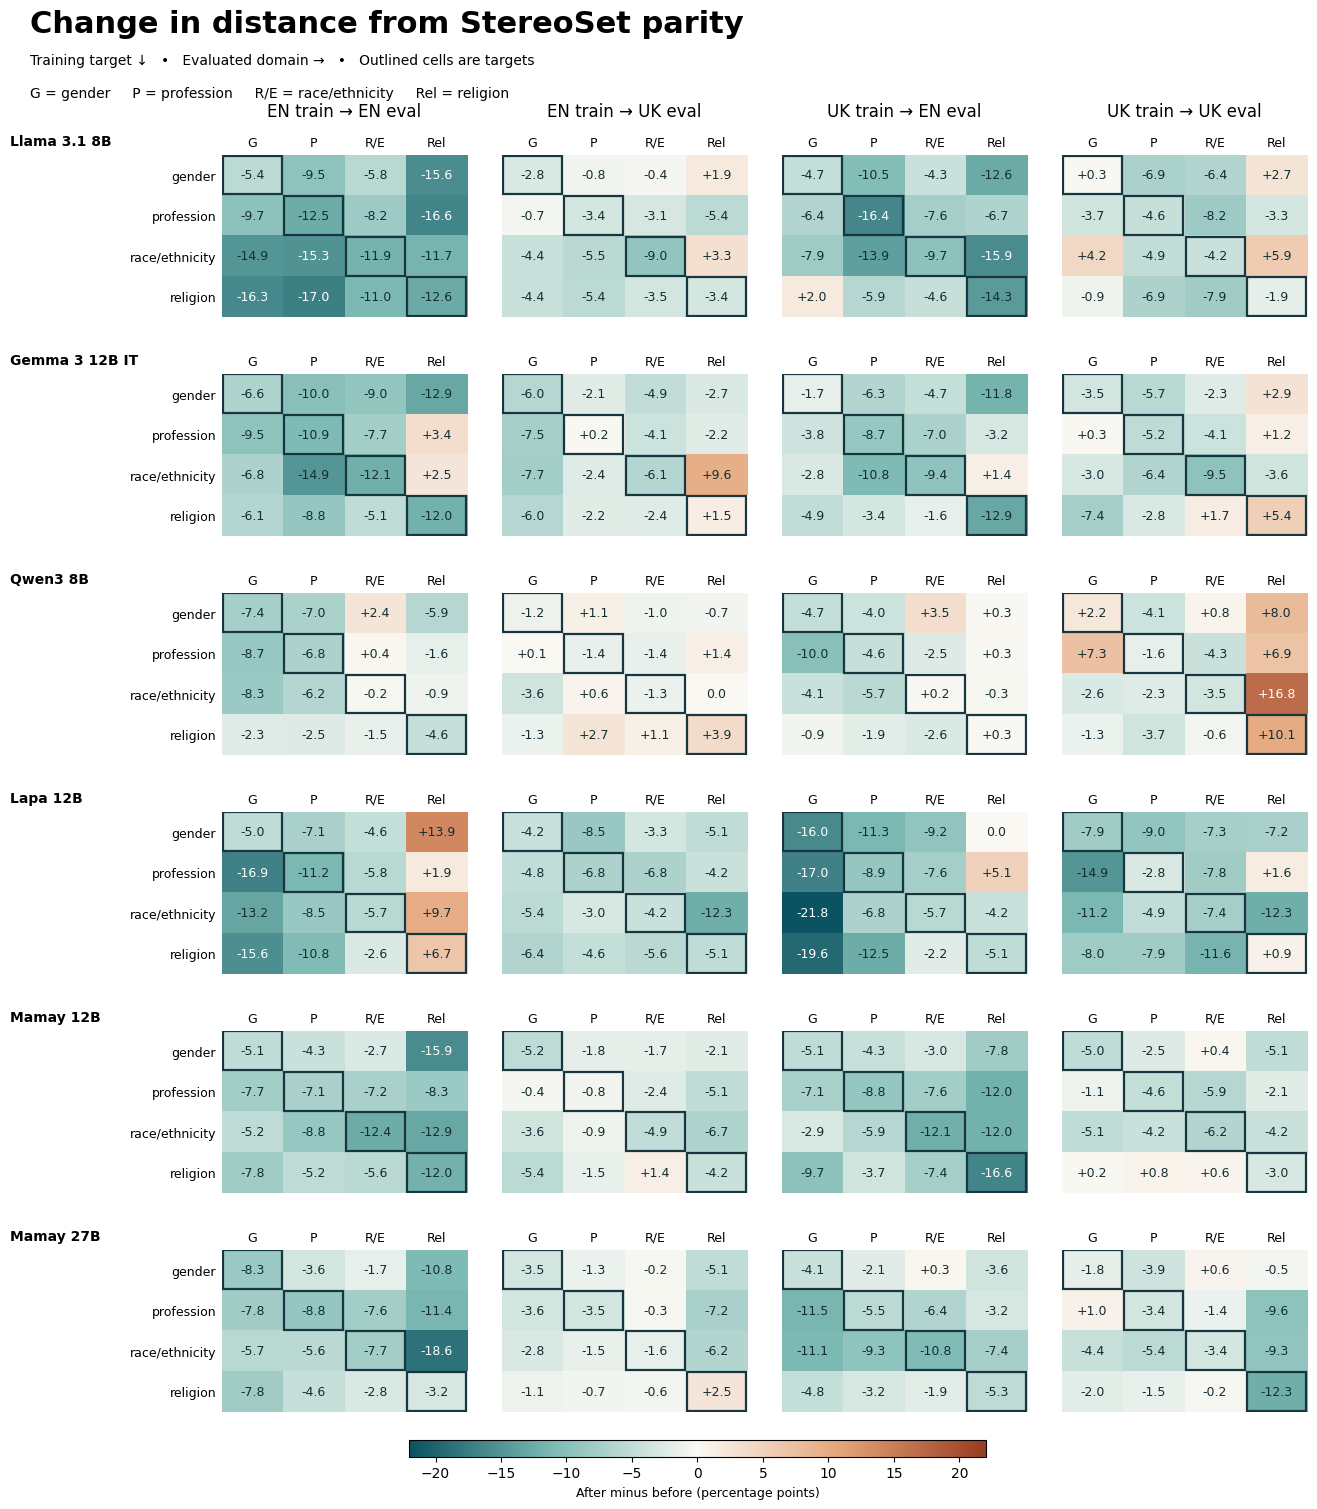

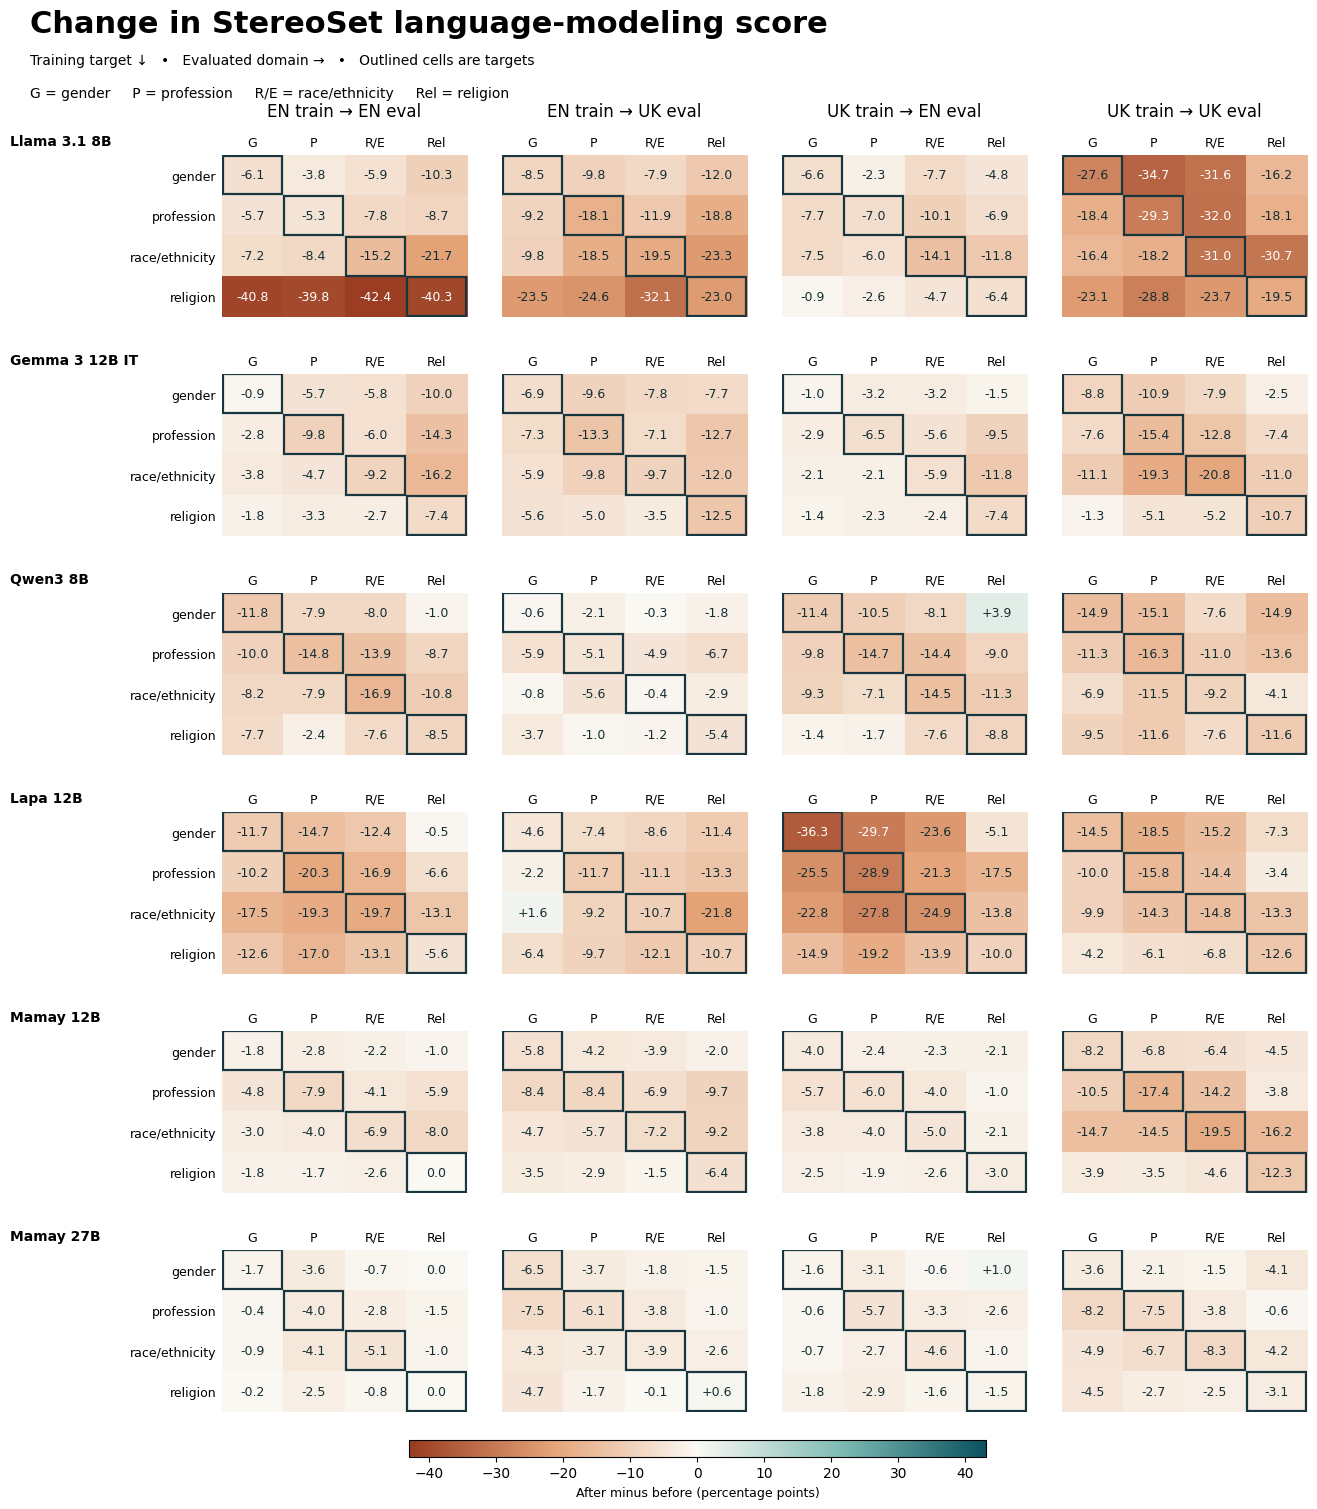

In [7]:
def heatmap(metric, title, good_sign, filename):
    limit = max(1, np.ceil(scores[metric].abs().max()))
    colors = ["#0b5260", "#7ebbb4", "#faf9f4", "#e5a479", "#993c21"]
    cmap = LinearSegmentedColormap.from_list(metric, colors if good_sign < 0 else colors[::-1])
    fig, axes = plt.subplots(len(models), len(routes), figsize=(13.4, 15.0))
    fig.subplots_adjust(left=0.17, right=0.98, top=0.89, bottom=0.052, wspace=0.14, hspace=0.35)
    fig.suptitle(title, x=0.027, y=0.987, ha="left", fontsize=22, weight="bold")
    fig.text(
        0.027, 0.950, "Training target ↓   •   Evaluated domain →   •   Outlined cells are targets"
    )
    fig.text(
        0.027, 0.928, "G = gender     P = profession     R/E = race/ethnicity     Rel = religion"
    )
    for i, model in enumerate(models):
        for j, (tr, ev) in enumerate(routes):
            ax = axes[i, j]
            panel = scores.loc[
                (scores.model == model) & (scores.train == tr) & (scores["eval"] == ev)
            ]
            values = panel.pivot(index="target", columns="evaluated", values=metric).loc[
                domains, domains
            ]
            mesh = ax.imshow(values, cmap=cmap, norm=Normalize(-limit, limit), aspect="auto")
            for (y, x), value in np.ndenumerate(values.to_numpy()):
                label = f"{value:+.1f}" if abs(value) >= 0.05 else "0.0"
                ax.text(
                    x,
                    y,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if abs(value) > 0.68 * limit else "#132D33",
                )
                if x == y:
                    ax.add_patch(
                        Rectangle(
                            (x - 0.48, y - 0.48), 0.96, 0.96, fill=False, color="#183640", lw=1.6
                        )
                    )
            ax.set_xticks(range(4), ["G", "P", "R/E", "Rel"], fontsize=9)
            ax.xaxis.tick_top()
            ax.set_yticks(
                range(4), [labels.get(d, d) for d in domains] if j == 0 else [""] * 4, fontsize=9
            )
            ax.tick_params(length=0, pad=4)
            ax.spines[:].set_visible(False)
            if i == 0:
                ax.set_title(f"{tr.upper()} train → {ev.upper()} eval", fontsize=12, pad=14)
        fig.text(
            0.012,
            axes[i, 0].get_position().y1 + 0.006,
            model.replace(" Instruct", ""),
            weight="bold",
        )
    bar = fig.colorbar(mesh, cax=fig.add_axes([0.31, 0.022, 0.43, 0.011]), orientation="horizontal")
    bar.set_label("After minus before (percentage points)", fontsize=9)
    fig.savefig(out / filename, dpi=160)
    plt.show()
    plt.close(fig)


heatmap("bias_change", "Change in distance from StereoSet parity", -1, "bias_heatmap.png")
heatmap("lms_change", "Change in StereoSet language-modeling score", 1, "lms_heatmap.png")

## WinoBias and BBQ
WinoBias reports the absolute pro–anti accuracy gap for occupational coreference. Controlled and natural are separate views. The natural views share 279 primary pairs. The Ukrainian panel also includes grammatical controls.

BBQ reports category-macro absolute bias separately by ambiguity condition. The category table preserves signed scores, eligible denominators and the non-unknown answer mass. A zero denominator can produce a convention-based endpoint with an unavailable paired change. Counts and means below use the native availability flag. The external CSV preserves pointwise paired intervals, valid bootstrap draws, accuracy and unknown-answer rates. Each external panel requested 1,000 draws.

In [8]:
external = external_rows(reports)
categories = bbq_categories(reports, external)
gaps = external.loc[
    ((external.scope == "overall_macro") & (external.metric == "absolute_bias_gap"))
    | (
        external.scope.str.startswith("category_macro / ")
        & (external.metric == "absolute_bias_macro")
    )
].copy()
gaps["panel"] = np.where(
    gaps.task.str.startswith("bbq"),
    "BBQ " + gaps.scope.str.split(" / ").str[-1],
    "WinoBias " + gaps.task.str.split("_").str[-1],
)
available = gaps.status.eq("available") & gaps.change.notna()
gaps["direction"] = np.select(
    [~available, gaps.change < -TOLERANCE, gaps.change > TOLERANCE],
    ["Unavailable", "Reduced", "Increased"],
    default="Unchanged",
)
display(
    pd.crosstab([gaps.panel, gaps["eval"]], gaps.direction).reindex(
        columns=["Reduced", "Increased", "Unchanged", "Unavailable"], fill_value=0
    )
)
external_means = (
    gaps.loc[available]
    .groupby(["model", "train", "eval", "panel"])
    .agg(before=("before", "mean"), after=("after", "mean"), available_targets=("change", "count"))
)
display(
    Markdown(
        "**Mean before → after across available training targets.** Counts in the exported summary identify missing BBQ comparisons."
    )
)
display(
    external_means.assign(score=before_after(external_means.before, external_means.after))
    .score.unstack("panel")
    .reindex(
        pd.MultiIndex.from_product([models, languages, languages], names=["model", "train", "eval"])
    )
)

direction                 Reduced  Increased  Unchanged  Unavailable
panel               eval                                            
BBQ ambiguous       en         38          7          0            3
                    uk         37          5          0            6
BBQ disambiguated   en         10         38          0            0
                    uk         14         34          0            0
WinoBias controlled en         28         20          0            0
                    uk         32         16          0            0
WinoBias natural    en         35         12          1            0
                    uk         43          5          0            0

**Mean before → after across available training targets.** Counts in the exported summary identify missing BBQ comparisons.

panel                            BBQ ambiguous BBQ disambiguated  \
model                 train eval                                   
Llama 3.1 8B Instruct en    en      15.6 → 2.4         3.2 → 4.3   
                            uk       9.5 → 1.8         3.5 → 3.4   
                      uk    en      15.6 → 4.1         3.2 → 3.6   
                            uk       9.5 → 1.3         3.5 → 2.7   
Gemma 3 12B IT        en    en      14.2 → 9.3         2.5 → 4.3   
                            uk       8.2 → 6.1         3.4 → 5.3   
                      uk    en     14.2 → 10.0         2.5 → 2.6   
                            uk       8.2 → 3.8         3.4 → 4.2   
Qwen3 8B              en    en       7.9 → 9.6         3.0 → 4.3   
                            uk       4.6 → 6.5         4.0 → 4.7   
                      uk    en       7.9 → 4.0         3.0 → 6.1   
                            uk       4.6 → 3.0         4.0 → 8.8   
Lapa 12B              en    en      22.6 → 6.7         2.6 → 4.7   
                            uk      10.7 → 3.6         3.3 → 5.1   
                      uk    en      22.6 → 9.8         2.6 → 4.5   
                            uk      10.7 → 6.6         3.3 → 6.0   
Mamay 12B             en    en      23.6 → 7.7         2.7 → 5.1   
                            uk       8.9 → 4.6         3.6 → 5.2   
                      uk    en     23.6 → 11.1         2.7 → 4.0   
                            uk       8.9 → 4.5         3.6 → 4.9   
Mamay 27B             en    en       9.1 → 4.3         3.0 → 5.4   
                            uk       9.0 → 4.2         2.8 → 5.9   
                      uk    en       9.1 → 6.2         3.0 → 5.0   
                            uk       9.0 → 5.4         2.8 → 4.4   

panel                            WinoBias controlled WinoBias natural  
model                 train eval                                       
Llama 3.1 8B Instruct en    en            41.5 → 2.9       63.3 → 5.2  
                            uk             6.0 → 2.3        2.2 → 0.5  
                      uk    en           41.5 → 13.6      63.3 → 15.7  
                            uk             6.0 → 0.0        2.2 → 2.1  
Gemma 3 12B IT        en    en           37.6 → 35.4      46.6 → 33.9  
                            uk           12.8 → 17.1       12.2 → 7.4  
                      uk    en           37.6 → 38.4      46.6 → 43.4  
                            uk           12.8 → 11.2       12.2 → 7.8  
Qwen3 8B              en    en           25.5 → 27.6      35.8 → 34.4  
                            uk             6.6 → 9.0       12.7 → 5.5  
                      uk    en           25.5 → 24.4      35.8 → 33.6  
                            uk             6.6 → 1.2       12.7 → 7.4  
Lapa 12B              en    en           41.8 → 12.3       47.0 → 8.9  
                            uk            12.7 → 3.9        9.7 → 1.5  
                      uk    en           41.8 → 36.3      47.0 → 33.3  
                            uk            12.7 → 8.8        9.7 → 6.5  
Mamay 12B             en    en           34.1 → 27.5      48.2 → 39.1  
                            uk           13.3 → 12.8       17.2 → 8.8  
                      uk    en           34.1 → 36.5      48.2 → 39.7  
                            uk           13.3 → 10.8       17.2 → 4.3  
Mamay 27B             en    en           21.5 → 22.7      33.2 → 30.6  
                            uk            8.5 → 10.2       12.5 → 8.6  
                      uk    en           21.5 → 24.7      33.2 → 32.6  
                            uk            8.5 → 11.1       12.5 → 8.0

## Export the underlying numbers
The domain CSV retains signed SS change, distance from parity, parity crossings, LMS, ICAT and support for all 384 domain comparisons. The external files retain the native metrics and uncertainty for all WinoBias and BBQ evaluations. The source index links each result to its saved report and receipt under the original JUPITER run root.

In [9]:
tables = {
    "stereoset_domains": scores,
    "target_and_off_target": target,
    "cross_language": transfer,
    "external_effects": external,
    "external_overview": external_means.reset_index(),
    "bbq_categories": categories,
    "sources": sources,
}
for name, table in tables.items():
    table.to_csv(out / f"{name}.csv", index=False)
display(
    pd.Series({name: len(table) for name, table in tables.items()}, name="exported rows").to_frame()
)

,exported rows
stereoset_domains,384
target_and_off_target,96
cross_language,192
external_effects,26688
external_overview,96
bbq_categories,2880
sources,384
